# StampDataset

Пример работы с классом `StampDataset`: поля объекта, записи индекса, кадр с прямоугольником клейма, аугментации и разбиение на train/test.

Пакет `dataset` лежит в корне репозитория. Снимки — в соседней папке: `stamps_coco_merged`, а ещё `ornaments` и `empty`.

In [1]:
import random
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader, Subset

here = Path.cwd().resolve()
repo = next(
    path for path in [here, here / "CeramicNet", *here.parents]
    if (path / "dataset" / "datasets.py").is_file()
)
data = next(
    path for path in [repo.parent, repo, here]
    if (path / "stamps_coco_merged").is_dir()
)
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from dataset import StampDataset, collate_stamps
from dataset.transforms import (
    Brightness,
    Compose,
    Defocus,
    Grayscale,
    HighContrast,
    HorizontalFlip,
    LowContrast,
    VerticalFlip,
)

font = Path("/System/Library/Fonts/Supplemental/Arial Unicode.ttf")
if font.is_file():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams["font.family"] = "Arial Unicode MS"

photos = next(
    path for path in data.iterdir()
    if path.is_dir()
    and (path / "stamps").is_dir()
    and (path / "ornaments").is_dir()
    and (path / "empty").is_dir()
)
print("repo", repo)
print("coco", data / "stamps_coco_merged")
print("photos", photos)

repo /Users/user/Education/YandexCamp/CeramicNet/CeramicNet
coco /Users/user/Education/YandexCamp/CeramicNet/stamps_coco_merged
photos /Users/user/Education/YandexCamp/CeramicNet/Клеймы 


## Объект датасета

`StampDataset` читает COCO в конструкторе. Пиксели в этот момент не читаются. `negative_dirs` добавляет снимки без клейма: у них пустые `boxes` и `labels`. Файл с тем же именем, что уже есть в json, второй раз не добавляется.

In [2]:
dataset = StampDataset(
    data / "stamps_coco_merged",
    model="default",
    negative_dirs=[photos / "ornaments", photos / "empty"],
)

print("len", len(dataset))
for name in ("root_dir", "model", "standard_size", "transform", "negative_dirs", "categories"):
    print(f"{name}: {getattr(dataset, name)}")
print("items:", len(dataset.items))
print("поля записи:", ", ".join(dataset.items[0]))

len 723
root_dir: /Users/user/Education/YandexCamp/CeramicNet/stamps_coco_merged
model: default
standard_size: None
transform: None
negative_dirs: (PosixPath('/Users/user/Education/YandexCamp/CeramicNet/Клеймы /ornaments'), PosixPath('/Users/user/Education/YandexCamp/CeramicNet/Клеймы /empty'))
categories: {1: 'kleimo'}
items: 723
поля записи: path, file_name, image_id, width, height, cipher, shot, boxes, labels


## Индекс

`self.items` хранит кадр до `transform` и до `standard_size`. `boxes` — xyxy в пикселях файла. Если клейма нет, `boxes` имеет форму `(0, 4)`, а `labels` — форму `(0,)`.

In [3]:
box_counts = Counter(len(item["boxes"]) for item in dataset.items)
folders = Counter(item["file_name"].split("/", 1)[0] for item in dataset.items)
print("боксов на кадр:", dict(sorted(box_counts.items())))
print("папки:", dict(folders))


def first(pred):
    return next(i for i, item in enumerate(dataset.items) if pred(item))


picked = {
    "одно клеймо": first(lambda item: len(item["boxes"]) == 1),
    "два клейма": first(lambda item: len(item["boxes"]) == 2),
    "ornaments": first(lambda item: item["file_name"].startswith("ornaments/")),
    "empty": first(lambda item: item["file_name"].startswith("empty/")),
}


def show_value(value):
    if isinstance(value, np.ndarray):
        text = np.array2string(value, precision=2)
        return f"shape={tuple(value.shape)} dtype={value.dtype} {text}"
    return repr(value)


for title, idx in picked.items():
    print(f"\n[{idx}] {title}")
    for key, value in dataset.items[idx].items():
        print(f"  {key}: {show_value(value)}")

боксов на кадр: {0: 469, 1: 251, 2: 3}
папки: {'stamps': 254, 'empty': 254, 'ornaments': 215}

[0] одно клеймо
  path: PosixPath('/Users/user/Education/YandexCamp/CeramicNet/stamps_coco_merged/images/default/stamps/БП11-Р01-тех-0400_7.png')
  file_name: 'stamps/БП11-Р01-тех-0400_7.png'
  image_id: 1
  width: 480
  height: 374
  cipher: 'БП11-Р01-тех-0400'
  shot: 7
  boxes: shape=(1, 4) dtype=float32 [[137.78 206.02 241.28 279.95]]
  labels: shape=(1,) dtype=int64 [1]

[39] два клейма
  path: PosixPath('/Users/user/Education/YandexCamp/CeramicNet/stamps_coco_merged/images/default/stamps/КБ-2014-Р2-0597_2.png')
  file_name: 'stamps/КБ-2014-Р2-0597_2.png'
  image_id: 40
  width: 480
  height: 490
  cipher: 'КБ-2014-Р2-0597'
  shot: 2
  boxes: shape=(2, 4) dtype=float32 [[233.59 299.7  344.37 404.1 ]
 [359.29 238.63 466.52 394.86]]
  labels: shape=(2,) dtype=int64 [1 1]

[508] ornaments
  path: PosixPath('/Users/user/Education/YandexCamp/CeramicNet/Клеймы /ornaments/БП11-Р01-Г01-0873_3.p

## Кадр и клейма

`dataset[i]` читает PNG, вызывает `transform`, затем вписывает кадр в `standard_size` и возвращает картинку `(3, H, W)` в диапазоне `[0, 1]` и словарь `target`.

Здесь `standard_size` не задан, поэтому боксы в `target` — те же пиксели, что в `self.items`. Прямоугольник рисуется по `x1, y1, x2, y2`. Справа — вырез вокруг клейма.

[0] stamps/БП11-Р01-тех-0400_7.png
  tensor: shape=(3, 374, 480) dtype=torch.float32 min=0.039 max=1.000
  target[boxes]: shape=(1, 4) dtype=torch.float32 [[137.78 206.02 241.28 279.95]]
  target[labels]: shape=(1,) dtype=torch.int64 [1]
  target[image_id]: 1
  target[cipher]: 'БП11-Р01-тех-0400'
  target[file_name]: 'stamps/БП11-Р01-тех-0400_7.png'
  target[orig_size]: (374, 480)
  target[scale]: (1.0, 1.0)
  target[pad]: (0, 0)


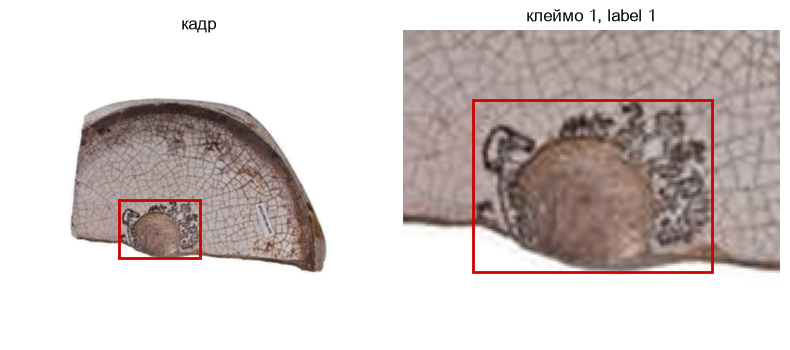

[39] stamps/КБ-2014-Р2-0597_2.png
  tensor: shape=(3, 490, 480) dtype=torch.float32 min=0.000 max=1.000
  target[boxes]: shape=(2, 4) dtype=torch.float32 [[233.59 299.7  344.37 404.1 ]
 [359.29 238.63 466.52 394.86]]
  target[labels]: shape=(2,) dtype=torch.int64 [1 1]
  target[image_id]: 40
  target[cipher]: 'КБ-2014-Р2-0597'
  target[file_name]: 'stamps/КБ-2014-Р2-0597_2.png'
  target[orig_size]: (490, 480)
  target[scale]: (1.0, 1.0)
  target[pad]: (0, 0)


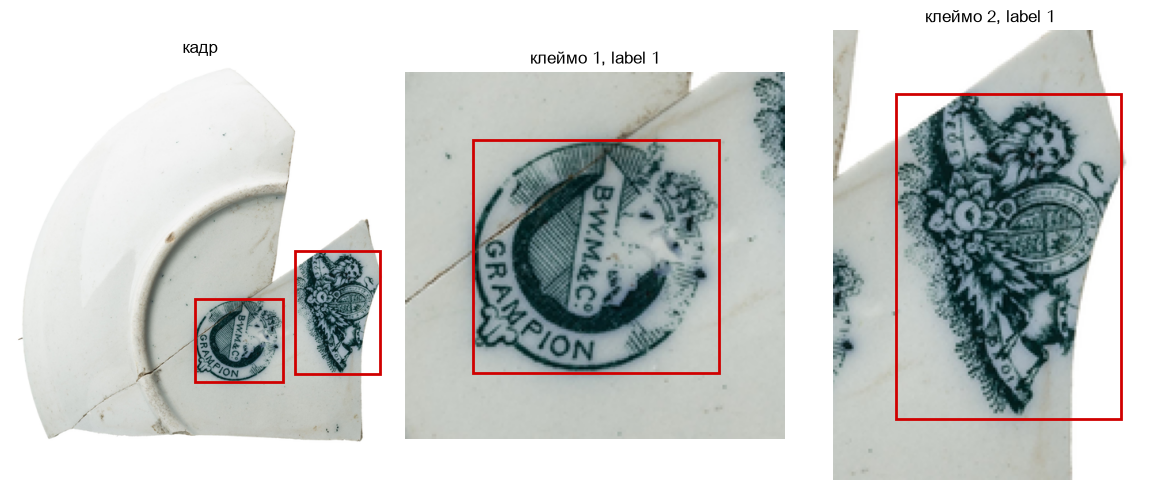

[508] ornaments/БП11-Р01-Г01-0873_3.png
  tensor: shape=(3, 295, 480) dtype=torch.float32 min=0.000 max=1.000
  target[boxes]: shape=(0, 4) dtype=torch.float32 []
  target[labels]: shape=(0,) dtype=torch.int64 []
  target[image_id]: 509
  target[cipher]: 'БП11-Р01-Г01-0873'
  target[file_name]: 'ornaments/БП11-Р01-Г01-0873_3.png'
  target[orig_size]: (295, 480)
  target[scale]: (1.0, 1.0)
  target[pad]: (0, 0)


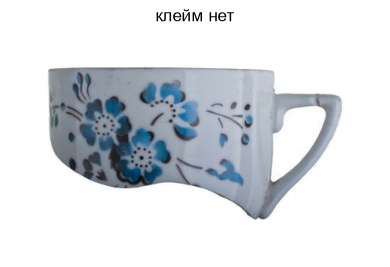

[254] empty/БП11-Р01-Г01-1395_7.png
  tensor: shape=(3, 326, 480) dtype=torch.float32 min=0.180 max=1.000
  target[boxes]: shape=(0, 4) dtype=torch.float32 []
  target[labels]: shape=(0,) dtype=torch.int64 []
  target[image_id]: 255
  target[cipher]: 'БП11-Р01-Г01-1395'
  target[file_name]: 'empty/БП11-Р01-Г01-1395_7.png'
  target[orig_size]: (326, 480)
  target[scale]: (1.0, 1.0)
  target[pad]: (0, 0)


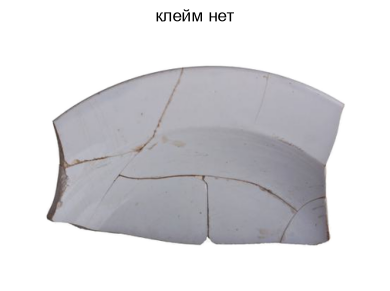

In [4]:
def draw_boxes(ax, picture, boxes, title):
    ax.imshow(picture)
    for box in boxes:
        x1, y1, x2, y2 = [float(value) for value in box]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="#d00000", linewidth=2))
    ax.set_title(title)
    ax.axis("off")


def show_element(source, idx):
    image, target = source[idx]
    picture = image.permute(1, 2, 0).numpy()
    boxes = target["boxes"].numpy()
    print(f"[{idx}] {target['file_name']}")
    print(
        f"  tensor: shape={tuple(image.shape)} dtype={image.dtype} "
        f"min={float(image.min()):.3f} max={float(image.max()):.3f}"
    )
    for key, value in target.items():
        if torch.is_tensor(value):
            text = np.array2string(value.detach().cpu().numpy(), precision=2)
            print(f"  target[{key}]: shape={tuple(value.shape)} dtype={value.dtype} {text}")
        else:
            print(f"  target[{key}]: {value!r}")

    if len(boxes) == 0:
        fig, ax = plt.subplots(figsize=(4, 5))
        draw_boxes(ax, picture, boxes, "клейм нет")
        plt.tight_layout()
        display(fig)
        plt.close(fig)
        return

    fig, axes = plt.subplots(1, 1 + len(boxes), figsize=(4 * (1 + len(boxes)), 5))
    draw_boxes(axes[0], picture, boxes, "кадр")
    height, width = picture.shape[:2]
    for number, box in enumerate(boxes, start=1):
        x1, y1, x2, y2 = [int(round(float(value))) for value in box]
        left, top = max(0, x1 - 30), max(0, y1 - 30)
        right, bottom = min(width, x2 + 30), min(height, y2 + 30)
        axes[number].imshow(picture[top:bottom, left:right])
        axes[number].add_patch(
            Rectangle((x1 - left, y1 - top), x2 - x1, y2 - y1, fill=False, edgecolor="#d00000", linewidth=2)
        )
        label = int(target["labels"][number - 1])
        axes[number].set_title(f"клеймо {number}, label {label}")
        axes[number].axis("off")
    plt.tight_layout()
    display(fig)
    plt.close(fig)


for idx in picked.values():
    show_element(dataset, idx)

## Аугментации

`transform` вызывается внутри `__getitem__` при каждом чтении кадра. Шаг срабатывает, если `random.random() < p`. При `p=0.5` это примерно половина чтений. На test `transform` не передают.

Ниже каждый шаг показан отдельно, слева исходный кадр. У всех примеров `p=1`, чтобы эффект был виден каждый раз. Отражения двигают прямоугольник. Цвет и размытие его не трогают.

HorizontalFlip [[238.72 206.02 342.22 279.95]]


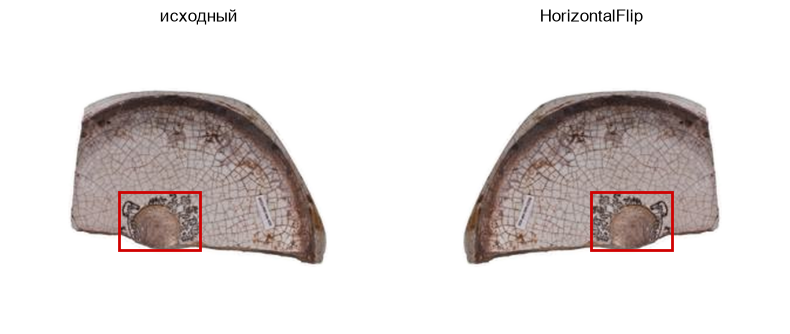

VerticalFlip [[137.78  94.05 241.28 167.98]]


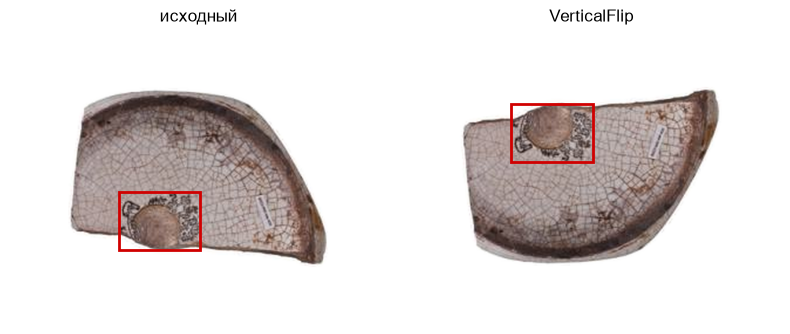

Grayscale [[137.78 206.02 241.28 279.95]]


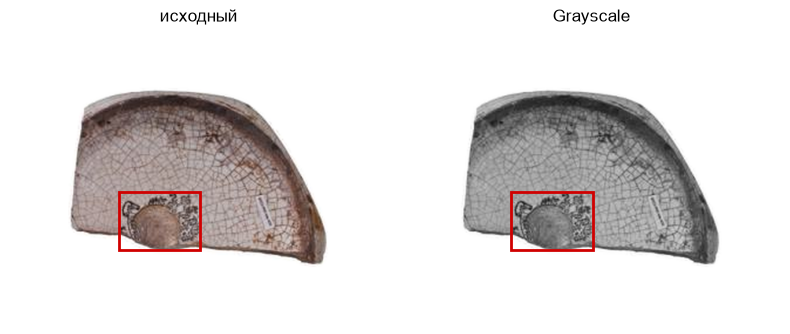

Brightness 0.6 [[137.78 206.02 241.28 279.95]]


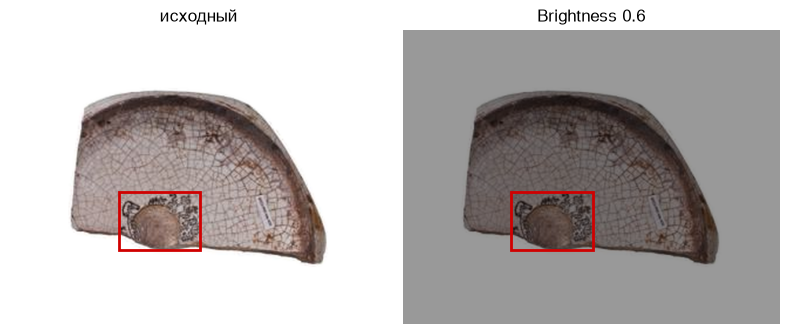

LowContrast 0.5 [[137.78 206.02 241.28 279.95]]


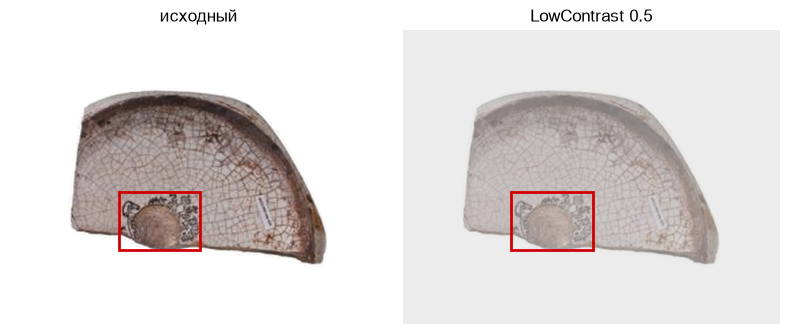

HighContrast 1.5 [[137.78 206.02 241.28 279.95]]


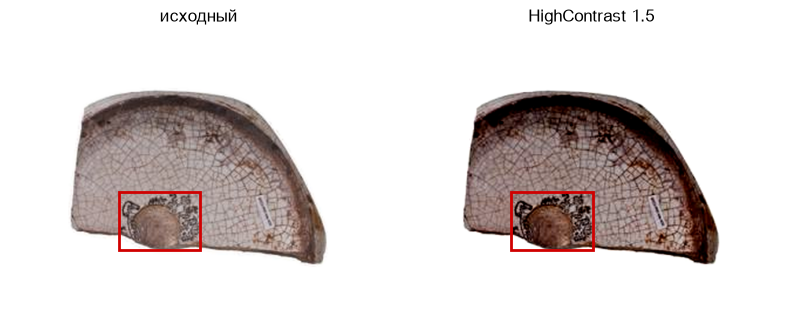

Defocus radius 3 [[137.78 206.02 241.28 279.95]]


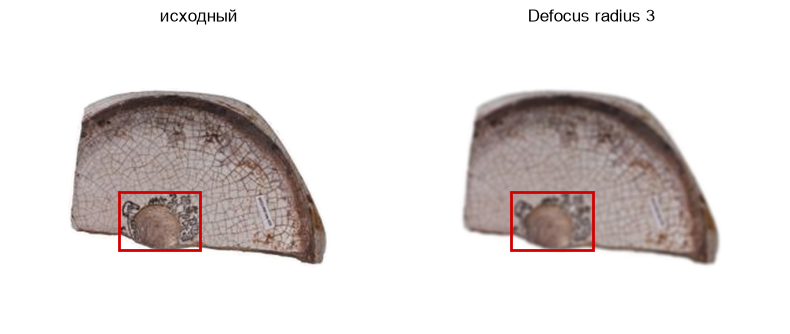

In [6]:
idx = picked["одно клеймо"]
image0, target0 = dataset[idx]
picture0 = image0.permute(1, 2, 0).numpy()
boxes0 = target0["boxes"].numpy()

examples = [
    ("HorizontalFlip", HorizontalFlip(p=1)),
    ("VerticalFlip", VerticalFlip(p=1)),
    ("Grayscale", Grayscale(p=1)),
    ("Brightness 0.6", Brightness(p=1, factor=(0.6, 0.6))),
    ("LowContrast 0.5", LowContrast(p=1, factor=(0.5, 0.5))),
    ("HighContrast 1.5", HighContrast(p=1, factor=(1.5, 1.5))),
    ("Defocus radius 3", Defocus(p=1, radius=3)),
]

for title, transform in examples:
    source = StampDataset(data / "stamps_coco_merged", transform=transform)
    assert source.items[idx]["file_name"] == dataset.items[idx]["file_name"]
    image, target = source[idx]
    print(title, np.array2string(target["boxes"].numpy(), precision=2))
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    draw_boxes(axes[0], picture0, boxes0, "исходный")
    draw_boxes(axes[1], image.permute(1, 2, 0).numpy(), target["boxes"].numpy(), title)
    plt.tight_layout()
    display(fig)
    plt.close(fig)

## Train и test

Класс сам выборку не делит. Индексы перемешиваются, 20% уходит в test, остальное остаётся в train. Аугментации нужны только train, поэтому это два объекта `StampDataset`: у них один `root_dir` и одни и те же индексы, но `transform` задан только у train. `standard_size=(640, 640)` вписывает кадр в квадрат с белыми полями и так же сдвигает боксы.

`collate_stamps` нужен, потому что число боксов на кадре разное. Он возвращает список картинок и список словарей.

При `num_workers > 0` воркеры наследуют один и тот же `random` и повторяют флипы. В `worker_init_fn` достаточно `random.seed(torch.initial_seed() % 2**32)`.

train 579 test 144
train transform <dataset.transforms.base.Compose object at 0x11d786b70>
test transform None
batch 4 (3, 640, 640)
ornaments/КБ-2014-Р5-0035_2.png (3, 640, 640) boxes (0, 4) scale (1.3333333333333333, 1.3333333333333333) pad (28, 0)
stamps/Нейш3А-2018-5707_11.png (3, 640, 640) boxes (1, 4) scale (1.3333333333333333, 1.3333333333333333) pad (6, 0)
stamps/Нейш3А-2018-5221_2.png (3, 640, 640) boxes (1, 4) scale (1.3333333333333333, 1.3333333333333333) pad (112, 0)
stamps/Нейш3А-2018-0115_2.png (3, 640, 640) boxes (1, 4) scale (1.332378223495702, 1.3333333333333333) pad (87, 0)


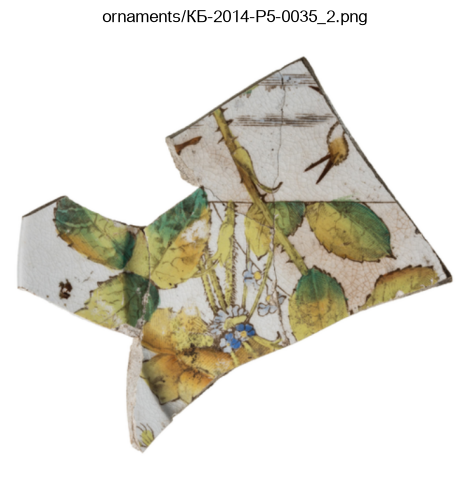

In [5]:
order = list(range(len(dataset)))
random.Random(0).shuffle(order)
n_test = int(len(order) * 0.2)
test_index, train_index = order[:n_test], order[n_test:]

common = dict(
    root_dir=data / "stamps_coco_merged",
    standard_size=(640, 640),
    model="default",
    negative_dirs=[photos / "ornaments", photos / "empty"],
)
train_data = StampDataset(
    **common,
    transform=Compose([
        HorizontalFlip(0.5),
        VerticalFlip(0.5),
        Grayscale(0.3),
        Brightness(0.5),
    ]),
)
test_data = StampDataset(**common)
train_set = Subset(train_data, train_index)
test_set = Subset(test_data, test_index)
print("train", len(train_set), "test", len(test_set))
print("train transform", train_data.transform)
print("test transform", test_data.transform)

loader = DataLoader(train_set, batch_size=4, shuffle=True, collate_fn=collate_stamps)
images, targets = next(iter(loader))
print("batch", len(images), tuple(images[0].shape))
for image, target in zip(images, targets):
    print(target["file_name"], tuple(image.shape), "boxes", tuple(target["boxes"].shape), "scale", target["scale"], "pad", target["pad"])

fig, ax = plt.subplots(figsize=(5, 5))
draw_boxes(
    ax,
    images[0].permute(1, 2, 0).numpy(),
    targets[0]["boxes"].numpy(),
    targets[0]["file_name"],
)
plt.tight_layout()
display(fig)
plt.close(fig)